Data Exploration and Quality check

In [1]:
import pandas as pd

In [2]:
df_dict = {'orders' : pd.read_csv(r'D:\DATA ANALYSIS\Projects\Brazilian E-commerce Public Dtaset by Olist\Brazilian E-commerce Public Dtaset by Olist\olist_orders_dataset.csv'),
     'customers' : pd.read_csv(r'D:\DATA ANALYSIS\Projects\Brazilian E-commerce Public Dtaset by Olist\Brazilian E-commerce Public Dtaset by Olist\olist_customers_dataset.csv'),
      'orders_items' : pd.read_csv(r'D:\DATA ANALYSIS\Projects\Brazilian E-commerce Public Dtaset by Olist\Brazilian E-commerce Public Dtaset by Olist\olist_order_items_dataset.csv'),
       'products' : pd.read_csv(r'D:\DATA ANALYSIS\Projects\Brazilian E-commerce Public Dtaset by Olist\Brazilian E-commerce Public Dtaset by Olist\olist_products_dataset.csv'),
        'review' : pd.read_csv(r'D:\DATA ANALYSIS\Projects\Brazilian E-commerce Public Dtaset by Olist\Brazilian E-commerce Public Dtaset by Olist\olist_order_reviews_dataset.csv'),
         'translation' : pd.read_csv(r'D:\DATA ANALYSIS\Projects\Brazilian E-commerce Public Dtaset by Olist\Brazilian E-commerce Public Dtaset by Olist\product_category_name_translation.csv'), }


In [3]:
for name, table in df_dict.items():
    print(name)
    #table.info()
    #print(name, table.shape)
    print(table.isna().sum())

orders
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64
customers
customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64
orders_items
order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64
products
product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm     

Data Analysis

In [4]:
orders = df_dict['orders'].copy()
customers = df_dict['customers'].copy()
orders_items = df_dict['orders_items'].copy()
products = df_dict['products'].copy()
review = df_dict['review'].copy()
translation = df_dict['translation'].copy()

In [5]:
orders

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00
...,...,...,...,...,...,...,...,...
99436,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28 00:00:00
99437,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02 00:00:00
99438,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27 00:00:00
99439,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15 00:00:00


In [6]:
# Converting dates to datetime format
orders['order_purchase_timestamp'] = pd.to_datetime(orders['order_purchase_timestamp'])
orders['order_approved_at'] = pd.to_datetime(orders['order_approved_at'])
orders['order_delivered_carrier_date'] = pd.to_datetime(orders['order_delivered_carrier_date'])
orders['order_delivered_customer_date'] = pd.to_datetime(orders['order_delivered_customer_date'])
orders['order_estimated_delivery_date'] = pd.to_datetime(orders['order_estimated_delivery_date'])

1.Monthly Sales

In [7]:
# 1.Monthly Sales
df_sales = orders.merge(orders_items, on='order_id')
filt = (df_sales['order_purchase_timestamp']  >= '2017-01-01') & (df_sales['order_purchase_timestamp']  < '2018-09-01') & (~df_sales['order_status'].isin(('canceled', 'unavailable')))  
df_sales = df_sales[filt].copy()
df_sales['sales'] = df_sales['price'] + df_sales['freight_value']
df_sales['purchase_month'] = df_sales['order_purchase_timestamp'].dt.to_period('M')
monthly = df_sales.groupby('purchase_month').agg(monthly_sales = ('sales', 'sum'), number_of_monthly_orders = ('order_id', 'nunique'))
monthly

,monthly_sales,number_of_monthly_orders
purchase_month,,
2017-01,136943.46,787
2017-02,283561.69,1718
2017-03,425617.96,2617
2017-04,405848.61,2377
2017-05,582710.83,3640
2017-06,499652.24,3205
2017-07,578753.73,3946
2017-08,661903.52,4272
2017-09,717102.72,4227


فروش ماهانه از ژانویه تا نوامبر ۲۰۱۷ رشد کرد و در نوامبر به حدود ۱٫۱۸ میلیون رسید. بعد از آن بین حدود ۰٫۹ تا ۱٫۲ میلیون نوسان دارد و رشد تند قبلی ادامه نمی‌یابد. قله‌ی نوامبر احتمالاً به تخفیف‌های پایان ماه مربوط است، ولی داده علت را نشان نمی‌دهد.

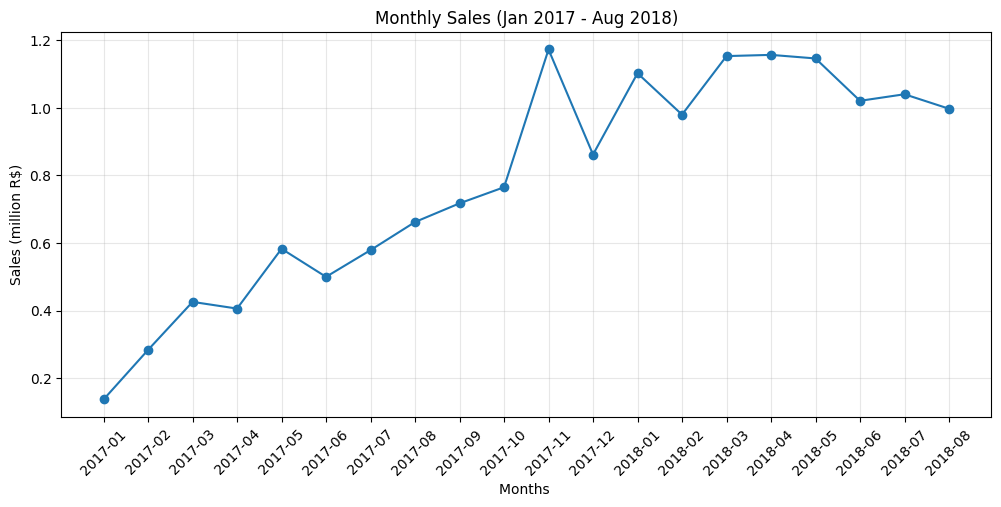

In [8]:
import matplotlib.pyplot as plt

months = monthly.index.astype('str')
sales = monthly['monthly_sales']/1000000
plt.figure(figsize=(12, 5))
plt.plot(months, sales, marker = 'o')
plt.title('Monthly Sales (Jan 2017 - Aug 2018)')
plt.xlabel('Months ')
plt.ylabel('Sales (million R$)')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.show()

2.Sales in each product category

In [9]:
oi = orders.merge(orders_items, on='order_id', how='left')
op = oi.merge(products, on='product_id', how='left')
df_category = op.merge(translation, on='product_category_name', how='left')
filt = (df_category['order_purchase_timestamp']  >= '2017-01-01') & (df_category['order_purchase_timestamp']  < '2018-09-01') & (~df_category['order_status'].isin(('canceled', 'unavailable')))  
df_category = df_category[filt].copy()
price_sum = df_category['price'].sum()
df_category['product_category_name_english'] = df_category['product_category_name_english'].fillna(df_category['product_category_name']).fillna('unknown')
category_price = df_category.groupby('product_category_name_english').agg(category_revenue = ('price', 'sum'))
category_price['Percentage'] = (category_price['category_revenue'] / category_price['category_revenue'].sum() * 100) . round(2)
category_price = category_price.sort_values('category_revenue')
category_price


,category_revenue,Percentage
product_category_name_english,,
security_and_services,283.29,0.00
fashion_childrens_clothes,569.85,0.00
cds_dvds_musicals,730.00,0.01
home_comfort_2,760.27,0.01
flowers,1110.04,0.01
...,...,...
computers_accessories,902922.70,6.71
sports_leisure,977728.77,7.27
bed_bath_table,1035485.07,7.70


ده دسته پرفروش با درصدها آورده شه که نشان میدهد دسته زیبایی و سلامت با 9.33 درصد بالاترین سهم در فروش را داشته و دسته های کادویی/ساعت و میزارایش/پاتختی به ترتیب دسته های پرفروش بعدی میباشند.

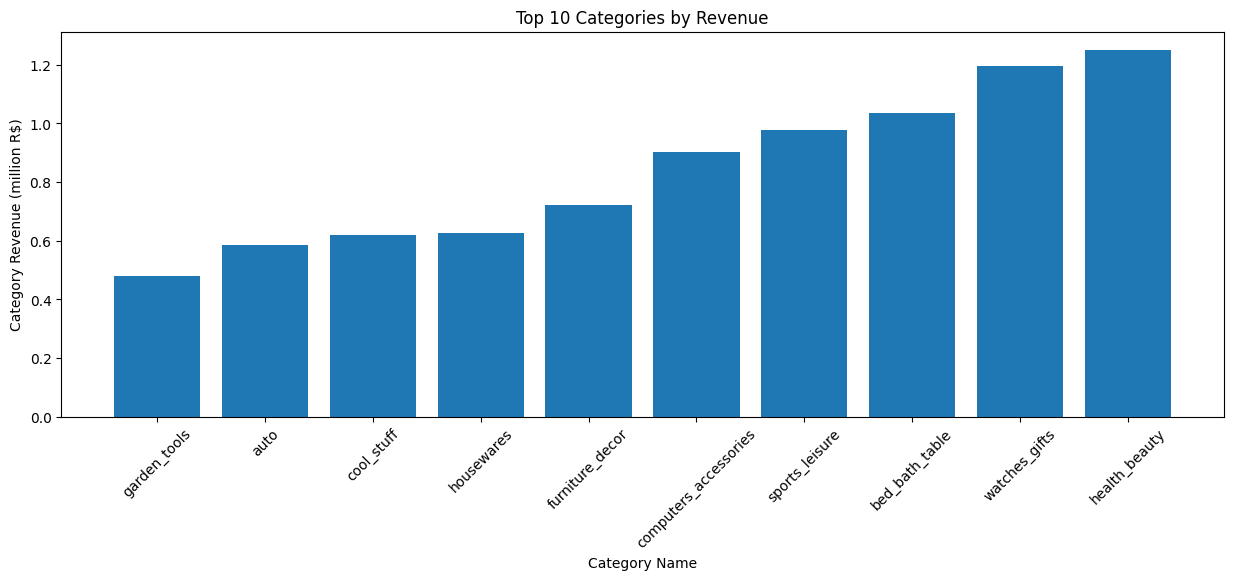

In [10]:
category = category_price.index[-10:]
category_revenue = category_price['category_revenue'].tail(10)/1000000
plt.figure(figsize=(15, 5))
plt.bar(category, category_revenue)
plt.title('Top 10 Categories by Revenue')
plt.xlabel('Category Name')
plt.ylabel('Category Revenue (million R$)')
plt.xticks(rotation=45)
plt.show()


[Text(0, 0, '3.57%'),
 Text(0, 0, '4.35%'),
 Text(0, 0, '4.61%'),
 Text(0, 0, '4.65%'),
 Text(0, 0, '5.37%'),
 Text(0, 0, '6.71%'),
 Text(0, 0, '7.27%'),
 Text(0, 0, '7.7%'),
 Text(0, 0, '8.88%'),
 Text(0, 0, '9.3%')]

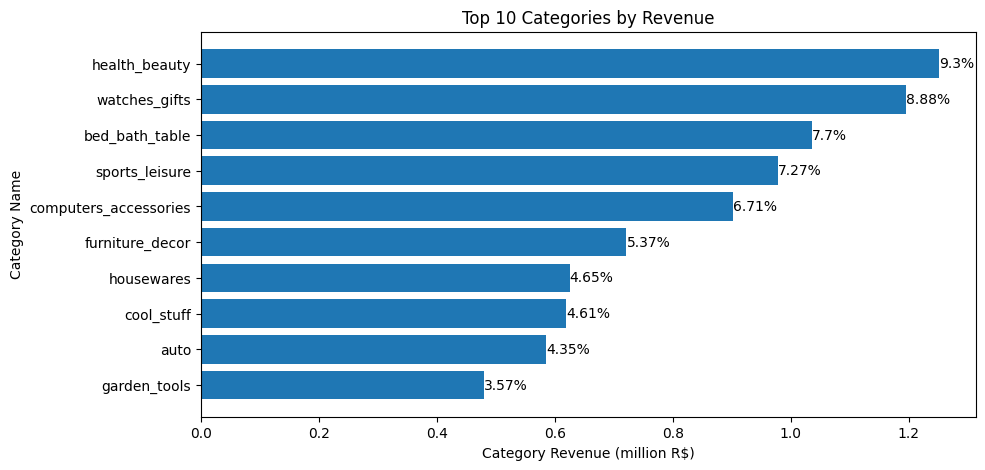

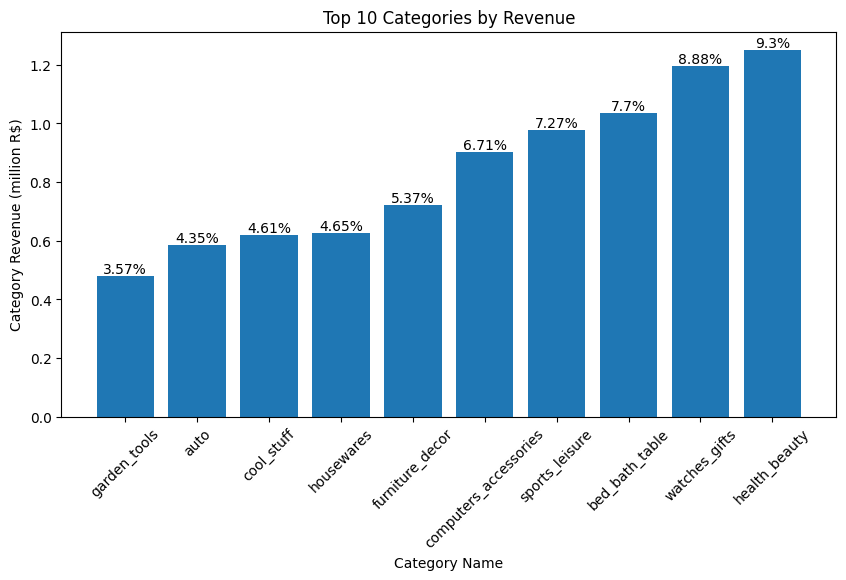

In [11]:
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(category, category_revenue)
plt.title('Top 10 Categories by Revenue')
plt.xlabel('Category Revenue (million R$)')
plt.ylabel('Category Name')
ax.bar_label(bars, labels=[f'{p}%' for p in category_price['Percentage'].tail(10)])

fig, ax = plt.subplots(figsize=(10, 5))
plt.title('Top 10 Categories by Revenue')
plt.xlabel('Category Name')
plt.ylabel('Category Revenue (million R$)')
plt.xticks(rotation=45)
bars = ax.bar(category, category_revenue)
ax.bar_label(bars, labels=[f'{p}%' for p in category_price['Percentage'].tail(10)])

-- 3.Delayed Deliveries and scores

In [12]:
average_review_score = review.groupby('order_id').agg(avg_score = ('review_score', 'mean'))
delayed_scores_df = orders.merge(average_review_score, on='order_id')
filt = (delayed_scores_df['order_purchase_timestamp']  >= '2017-01-01') & (delayed_scores_df['order_purchase_timestamp'] < '2018-09-01') & (delayed_scores_df['order_status'] == 'delivered') & (delayed_scores_df['order_delivered_customer_date'].notna())
delayed_scores = delayed_scores_df[filt].copy()
delayed_scores
a = delayed_scores['order_delivered_customer_date'].dt.normalize()
b = delayed_scores['order_estimated_delivery_date'].dt.normalize()
delayed_scores['delay_days'] = (a - b).dt.days

labels = ['Early Delivery', 'On time', '1-7 days', '8-30 days', '>30 days']
bins = [float('-inf'), -1, 0, 7, 30, float('inf')]
delayed_scores['delay_condition'] = pd.cut(delayed_scores['delay_days'], bins=bins, labels=labels)
delayed_review_scores_df = delayed_scores.groupby('delay_condition', observed=True) .agg(average_review_score = ('avg_score', 'mean'), number_of_orders = ('order_id', 'nunique')) 

delayed_review_scores_df.sort_values('average_review_score', ascending=False)


,average_review_score,number_of_orders
delay_condition,,
Early Delivery,4.295086,87902
On time,4.035547,1280
1-7 days,2.715060,3599
>30 days,2.059451,328
8-30 days,1.649735,2451


امتیاز با شدت تأخیر کم می‌شود: از ۴٫۳ (زودتر) و ۴٫۰۴ (به‌موقع) به ۲٫۷۲ برای ۱ تا ۷ روز دیر و ۱٫۶۵ برای ۸ تا ۳۰ روز.
گروه «بیش از ۳۰ روز» (۲٫۰۶) از گروه قبلی بهتر است، با فقط ۳۲۸ سفارش. علت را داده نمی‌گوید.

[Text(0, 0, 'n=87902'),
 Text(0, 0, 'n=1280'),
 Text(0, 0, 'n=3599'),
 Text(0, 0, 'n=2451'),
 Text(0, 0, 'n=328')]

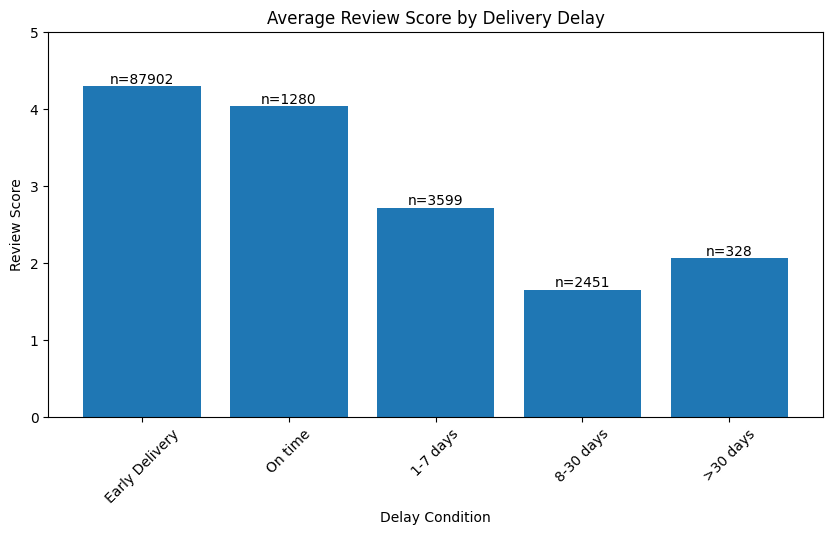

In [13]:
delay_condition = delayed_review_scores_df.index
average_review_score = delayed_review_scores_df['average_review_score']
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(delay_condition, average_review_score)
plt.title('Average Review Score by Delivery Delay')
plt.xlabel('Delay Condition')
plt.ylabel('Review Score')
plt.xticks(rotation=45)
plt.ylim(0, 5)
ax.bar_label(bars, labels=[f'n={p}' for p in delayed_review_scores_df['number_of_orders']])

Saving Dataframes to csv files

In [ ]:
'''monthly.reset_index()
monthly.to_csv('Monthly_Sales.csv')'''

'''category_price.reset_index()
category_price.to_csv('Category_Revenue.csv')'''

'''delayed_review_scores_df.reset_index()
delayed_review_scores_df.to_csv('Review_by_Delay.csv')'''


97905